# Time Series — Compact Working Notebook

A smaller notebook for the current forecasting work. It skips the old notebook's AAPL exploration, repeated plots, differencing experiments, walk-forward experiment, exogenous-variable experiment, and Auto-ARIMA search.

**Included:** AirPassengers data, chronological 80/20 split, Seasonal Naive vs SARIMA vs Prophet, model configuration check, and SARIMA residual diagnostics.

The final three-model comparison used SARIMA **without exogenous regressors**. The December-indicator experiment was separate.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.datasets import get_rdataset
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from prophet import Prophet
except ImportError:
    Prophet = None
    print("Prophet is not installed. If needed, run: %pip install prophet")

## 1. Load AirPassengers and make the same chronological split

We keep the first 80% for training and the last 20% for testing. Time series should not be randomly shuffled.

In [4]:
df = get_rdataset("AirPassengers").data.copy()
df["ds"] = pd.date_range("1949-01-01", periods=len(df), freq="MS")
df = df.rename(columns={"value": "y"})[["ds", "y"]]

split_idx = int(len(df) * 0.8)
train = df.iloc[:split_idx].copy()
test = df.iloc[split_idx:].copy()
y_train = train.set_index("ds")["y"]
y_test = test["y"].to_numpy()

print(f"Train: {train.ds.min():%Y-%m} to {train.ds.max():%Y-%m} ({len(train)} months)")
print(f"Test:  {test.ds.min():%Y-%m} to {test.ds.max():%Y-%m} ({len(test)} months)")
print("Season length: 12 months")
display(df.head())

Train: 1949-01 to 1958-07 (115 months)
Test:  1958-08 to 1960-12 (29 months)
Season length: 12 months


,ds,y
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


## 2. Seasonal Naive baseline

Predict each test month using the value from the same month one year earlier.

In [5]:
seasonal_naive = np.tile(
    y_train.iloc[-12:].to_numpy(),
    int(np.ceil(len(y_test) / 12))
)[:len(y_test)]

## 3. Fit SARIMA

Non-seasonal order `(1, 1, 1)`, seasonal order `(1, 1, 1, 12)`. No `exog=` argument is supplied.

In [6]:
sarima_fit = SARIMAX(
    y_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_pred = sarima_fit.forecast(steps=len(y_test)).to_numpy()

print("Non-seasonal order:", sarima_fit.model.order)
print("Seasonal order:", sarima_fit.model.seasonal_order)
print("Number of exogenous regressors:", getattr(sarima_fit.model, "k_exog", "not available"))

/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Non-seasonal order: (1, 1, 1)
Seasonal order: (1, 1, 1, 12)
Number of exogenous regressors: 0


## 4. Fit Prophet (if installed)

Prophet uses the same training period and predicts the same test months.

In [7]:
prophet_pred = None
if Prophet is not None:
    prophet_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False
    )
    prophet_model.fit(train[["ds", "y"]])
    prophet_pred = prophet_model.predict(test[["ds"]])["yhat"].to_numpy()
else:
    print("Skipping Prophet because it is not installed.")

/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
16:17:40 - cmdstanpy - INFO - Chain [1] start processing
16:17:41 - cmdstanpy - INFO - Chain [1] done processing


## 5. Compare all models on the same test months

Lower MAE and RMSE are better on this test set. RMSE penalizes larger errors more strongly.

In [8]:
predictions = {
    "Seasonal Naive": seasonal_naive,
    "SARIMA": sarima_pred,
}
if prophet_pred is not None:
    predictions["Prophet"] = prophet_pred

results = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred))
    }
    for name, pred in predictions.items()
]).sort_values("RMSE").reset_index(drop=True)

display(results.round(2))
assert all(len(pred) == len(y_test) for pred in predictions.values())

,Model,MAE,RMSE
0,SARIMA,25.27,31.79
1,Prophet,33.93,41.34
2,Seasonal Naive,64.76,75.23


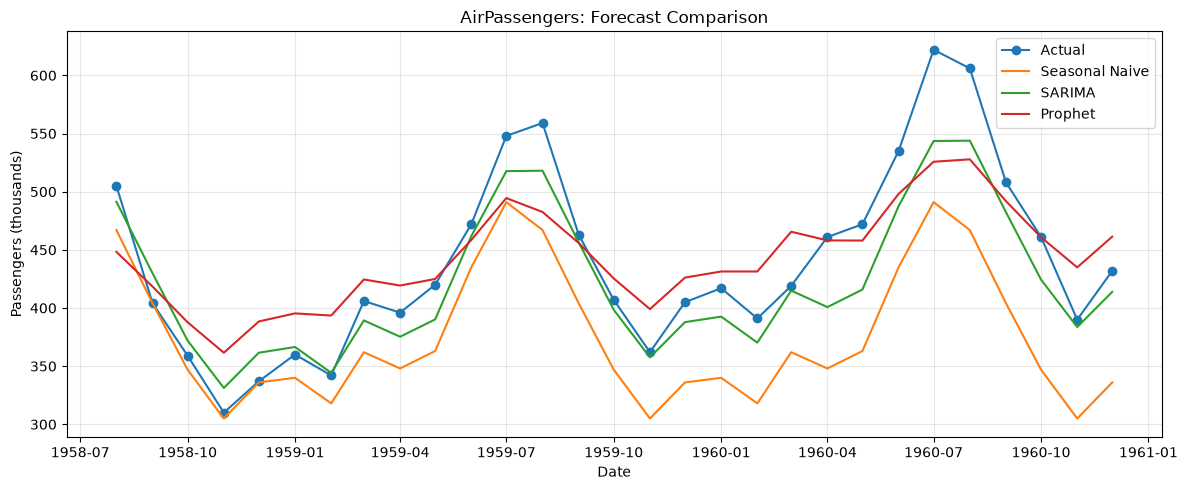

In [9]:
plt.figure(figsize=(12, 5))
plt.plot(test["ds"], y_test, label="Actual", marker="o")
for name, pred in predictions.items():
    plt.plot(test["ds"], pred, label=name)
plt.title("AirPassengers: Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. SARIMA residual diagnostics

The Ljung–Box test checks whether residual autocorrelation is detectable at the tested lags. A p-value above 0.05 means we fail to reject the no-autocorrelation null; it does not prove that all autocorrelation is absent.

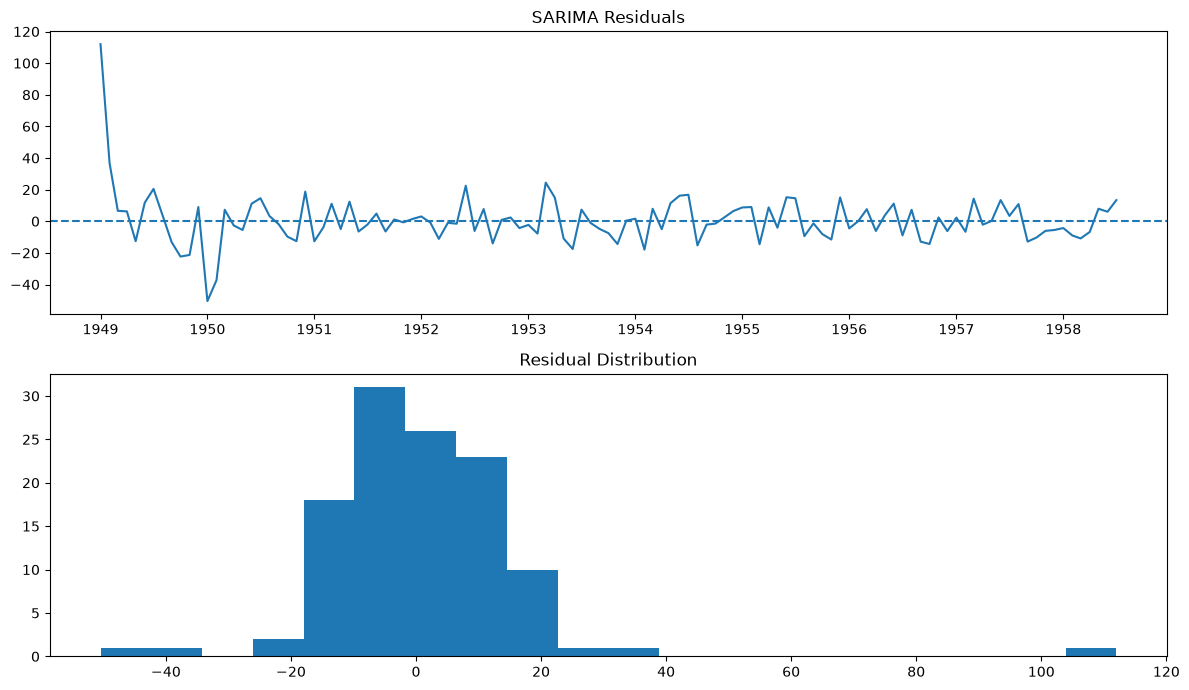

,lb_stat,lb_pvalue
12,16.210366,0.181790
24,24.152113,0.452927


In [10]:
residuals = sarima_fit.resid.dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(residuals)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("SARIMA Residuals")
axes[1].hist(residuals, bins=20)
axes[1].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

display(acorr_ljungbox(residuals, lags=[12, 24], return_df=True))

## Previous run — reference results

| Model | MAE | RMSE |
|---|---:|---:|
| SARIMA | 25.27 | 31.79 |
| Prophet | 33.93 | 41.34 |
| Seasonal Naive | 64.76 | 75.23 |

These are the previously reported results, not guaranteed outputs for every re-run. SARIMA performed best on that test split.

**Not included:** the separate SARIMAX experiment using a December indicator as an exogenous feature. Keep it separate from this baseline comparison.